Mục tiêu: Kiểm tra độc lập đầu ra Bước 03, tìm rủi ro của cách chuẩn hóa trước khi huấn luyện IF, AE, LOF.

Nguyên tắc:
- Đầu vào gốc chỉ gồm 7 trường ticker, date, open, high, low, close, volume.
- Không tạo nhãn bất thường thật, không fit mô hình, không hiệu chỉnh ngưỡng.
- Kiểm tra TOÁN HỌC và TÍNH TOÀN VẸN cho tất cả hàng. Chỉ khảo sát phân bố để cân nhắc phương pháp trên Train và Validation select.
- Không dùng Validation calibrate hoặc Test để chọn cửa sổ, mức sàn hay cấu hình.
- Các mức |z_gap| > 30 và tỷ lệ sử dụng sàn > 25% chỉ là mốc gọi rà soát, không phải ngưỡng phát hiện bất thường hay điều kiện đúng/sai của mô hình.
Đầu ra: bảng kiểm tra, bảng các gap cần rà soát, mức sử dụng sàn theo mã, độ nhạy mức sàn, biểu đồ và báo cáo kết luận.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

# 1) CẤU HÌNH THƯ MỤC — sửa nếu các file nằm chỗ khác
DATA_DIR = Path(r"outputs/03_feature_engineering")
STEP02_DIR = Path(r"outputs/02_time_split_70_15_15")
OUTPUT_DIR = Path(r"outputs/04_feature_validation")

# Cho phép đặt các file Bước 03 ngay cạnh notebook để chạy copy-paste.
needed_files = [
    "03_features_all.csv",
    "03_model_ready_development.csv",
    "03_feature_coverage_by_ticker.csv",
    "03_feature_status_summary.csv",
    "03_feature_config.json",
]
if not all((DATA_DIR / name).is_file() for name in needed_files):
    if all(Path(name).is_file() for name in needed_files):
        DATA_DIR = Path(".")
    else:
        raise FileNotFoundError(
            "Không tìm thấy đủ 5 file Bước 03. Hãy sửa DATA_DIR. "
            f"Đang thử: {DATA_DIR.resolve()}"
        )
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SOURCE = ["ticker", "date", "open", "high", "low", "close", "volume"]
KEY = ["ticker", "date"]
PRICE = ["open", "high", "low", "close"]
NAMES = ["gap", "intraday", "range", "volume"]
RAW = {"gap": "raw_gap", "intraday": "raw_intraday", "range": "raw_range", "volume": "raw_log_volume"}
ZS = [f"z_{name}" for name in NAMES]
QA_GAP_ABS_Z = 30.0        # Cờ rà soát, KHÔNG phải ngưỡng phát hiện bất thường
QA_FLOOR_PCT = 25.0       # Cờ rà soát ảnh hưởng theo mã, KHÔNG phải tiêu chuẩn tối ưu
FLOOR_MULTIPLIERS = [0.5, 1.0, 2.0]  # Thử độ nhạy, chưa thay đổi cấu hình chính

checks = []
def passed(description):
    checks.append({"check": description, "status": "PASS"})
    print("[PASS]", description)

def assert_close(a, b, name, atol=1e-10, rtol=1e-10):
    np.testing.assert_allclose(
        np.asarray(a, dtype=float), np.asarray(b, dtype=float),
        equal_nan=True, atol=atol, rtol=rtol, err_msg=name,
    )

print("Bước 03:", DATA_DIR.resolve())
print("Bước 04 xuất tại:", OUTPUT_DIR.resolve())

Bước 03: D:\LUẬN VĂN\stock-news-anomaly-project\Stocks\notebooks\outputs\03_feature_engineering
Bước 04 xuất tại: D:\LUẬN VĂN\stock-news-anomaly-project\Stocks\notebooks\outputs\04_feature_validation


In [3]:
all_df = pd.read_csv(DATA_DIR / "03_features_all.csv", encoding="utf-8-sig")
dev_df = pd.read_csv(DATA_DIR / "03_model_ready_development.csv", encoding="utf-8-sig")
coverage_file = pd.read_csv(DATA_DIR / "03_feature_coverage_by_ticker.csv", encoding="utf-8-sig")
status_file = pd.read_csv(DATA_DIR / "03_feature_status_summary.csv", encoding="utf-8-sig")
with (DATA_DIR / "03_feature_config.json").open(encoding="utf-8") as f:
    config = json.load(f)

required = SOURCE + ["split", "val_role", "prev_valid_close", *RAW.values(), *ZS, "feature_status", "is_model_ready"]
for name in NAMES:
    required += [f"hist_median_{name}", f"hist_mad_{name}", f"mad_zero_{name}", f"floor_applied_{name}"]
if set(required) - set(all_df.columns):
    raise ValueError(f"03_features_all.csv thiếu cột: {sorted(set(required) - set(all_df.columns))}")
if set([*KEY, "split", "val_role", *ZS]) - set(dev_df.columns):
    raise ValueError("03_model_ready_development.csv thiếu cột bắt buộc")

for d in [all_df, dev_df]:
    d["date"] = pd.to_datetime(d["date"], format="%Y-%m-%d", errors="raise")
    d["ticker"] = d["ticker"].astype("string").str.strip()

all_df = all_df.sort_values(KEY).reset_index(drop=True)
dev_df = dev_df.sort_values(KEY).reset_index(drop=True)

assert len(all_df) > 0 and all_df["ticker"].nunique() == 13
assert not all_df.duplicated(KEY).any()
assert not dev_df.duplicated(KEY).any()
assert all_df[SOURCE].notna().all().all()
assert np.isfinite(all_df[PRICE + ["volume"]].to_numpy(dtype=float)).all()
assert (all_df[PRICE] > 0).all().all()
assert (all_df["volume"] >= 0).all()
assert (all_df["high"] >= all_df[["open", "close", "low"]].max(axis=1)).all()
assert (all_df["low"] <= all_df[["open", "close", "high"]].min(axis=1)).all()
assert set(all_df["split"]) == {"train", "val", "test"}
assert all_df.groupby("date")["split"].nunique().eq(1).all()
assert all_df.groupby("date")["val_role"].nunique().eq(1).all()
assert all_df.loc[all_df["split"] != "val", "val_role"].eq("not_applicable").all()
assert all_df.loc[all_df["split"] == "val", "val_role"].isin(["select", "calibrate"]).all()
assert all_df.loc[all_df["split"] == "train", "date"].max() < all_df.loc[all_df["split"] == "val", "date"].min()
assert all_df.loc[all_df["split"] == "val", "date"].max() < all_df.loc[all_df["split"] == "test", "date"].min()
sel_dates = all_df.loc[(all_df["split"] == "val") & (all_df["val_role"] == "select"), "date"]
cal_dates = all_df.loc[(all_df["split"] == "val") & (all_df["val_role"] == "calibrate"), "date"]
assert sel_dates.max() < cal_dates.min()
passed("13 mã, khóa duy nhất, OHLCV hợp lệ và mốc thời gian không chồng lấn")

if config.get("window_prior_valid_feature_values_per_ticker") is None:
    raise ValueError("Cấu hình không ghi rõ W")
W = int(config["window_prior_valid_feature_values_per_ticker"])
FACTOR = float(config["mad_normal_factor"])
Q = float(config["train_floor_quantile_positive_mad_scales"])
FLOORS = {n: float(config["train_floors"][n]) for n in NAMES}
assert W >= 2 and FACTOR > 0 and 0 < Q < 1
assert all(np.isfinite(x) and x > 0 for x in FLOORS.values())
assert ZS == config["features_for_model"]
print(f"W={W}; hệ số MAD={FACTOR}; phân vị mức sàn={Q}; chỉ Train dùng để fit mức sàn")

[PASS] 13 mã, khóa duy nhất, OHLCV hợp lệ và mốc thời gian không chồng lấn
W=60; hệ số MAD=1.4826; phân vị mức sàn=0.1; chỉ Train dùng để fit mức sàn


In [4]:
prev_close = all_df.groupby("ticker", sort=False)["close"].shift(1)
independent_raw = {
    "gap": np.log(all_df["open"].to_numpy() / prev_close.to_numpy()),
    "intraday": np.log(all_df["close"].to_numpy() / all_df["open"].to_numpy()),
    "range": np.log(all_df["high"].to_numpy() / all_df["low"].to_numpy()),
    "volume": np.log1p(all_df["volume"].to_numpy()),
}
assert_close(all_df["prev_valid_close"], prev_close, "Close phiên trước")
for name in NAMES:
    assert_close(all_df[RAW[name]], independent_raw[name], f"Công thức {name}")

# gap + intraday = log(Close hiện tại / Close trước), nơi đủ lịch sử
ok_prev = prev_close.notna().to_numpy()
assert_close(
    independent_raw["gap"][ok_prev] + independent_raw["intraday"][ok_prev],
    np.log(all_df["close"].to_numpy()[ok_prev] / prev_close.to_numpy()[ok_prev]),
    "Đồng nhất thức lợi suất log",
)
flat = all_df["high"].eq(all_df["low"]).to_numpy()
assert np.allclose(independent_raw["range"][flat], 0, atol=1e-14)
assert all_df.loc[flat, PRICE].notna().all().all()
passed("Bốn công thức thô, Close trước, đồng nhất thức lợi suất và phiên High=Low")

[PASS] Bốn công thức thô, Close trước, đồng nhất thức lợi suất và phiên High=Low


In [5]:
def rolling_previous_window(x, w):
    """Trả về median, MAD của w giá trị trước mỗi vị trí, không dùng hiện tại."""
    x = np.asarray(x, dtype=float)
    median = np.full(len(x), np.nan, dtype=float)
    mad = np.full(len(x), np.nan, dtype=float)
    if len(x) <= w:
        return median, mad
    past = sliding_window_view(x, w)[:-1]
    complete = np.isfinite(past).all(axis=1)
    if complete.any():
        windows = past[complete]
        m = np.median(windows, axis=1)
        median[w:][complete] = m
        mad[w:][complete] = np.median(np.abs(windows - m[:, None]), axis=1)
    return median, mad

reference = {}
for name in NAMES:
    median_out = np.full(len(all_df), np.nan)
    mad_out = np.full(len(all_df), np.nan)
    for ticker, indices in all_df.groupby("ticker", sort=False).indices.items():
        idx = np.asarray(indices)
        median_out[idx], mad_out[idx] = rolling_previous_window(independent_raw[name][idx], W)
    reference[name] = (median_out, mad_out)
    assert_close(all_df[f"hist_median_{name}"], median_out, f"Rolling median {name}")
    assert_close(all_df[f"hist_mad_{name}"], mad_out, f"Rolling MAD {name}")
passed("Rolling median/MAD W giá trị quá khứ của từng mã")

ready_expected = np.ones(len(all_df), dtype=bool)
for name in NAMES:
    ready_expected &= np.isfinite(independent_raw[name])
    ready_expected &= np.isfinite(reference[name][0])
    ready_expected &= np.isfinite(reference[name][1])
assert np.array_equal(all_df["is_model_ready"].to_numpy(dtype=bool), ready_expected)

train_ready = ready_expected & all_df["split"].eq("train").to_numpy()
for name in NAMES:
    median, mad = reference[name]
    scale = FACTOR * mad
    positive_train_scales = scale[train_ready & np.isfinite(scale) & (scale > 0)]
    assert len(positive_train_scales) > 0, f"Train thiếu MAD dương: {name}"
    floor_independent = float(np.quantile(positive_train_scales, Q))
    np.testing.assert_allclose(floor_independent, FLOORS[name], rtol=1e-11, atol=1e-12)
    z = (independent_raw[name] - median) / np.maximum(scale, floor_independent)
    z[~ready_expected] = np.nan
    assert_close(all_df[f"z_{name}"], z, f"z_{name}")
    assert np.array_equal(
        all_df[f"mad_zero_{name}"].to_numpy(dtype=bool),
        ready_expected & (mad == 0),
    ), f"Cờ MAD bằng 0 chưa khớp: {name}"
    assert np.array_equal(
        all_df[f"floor_applied_{name}"].to_numpy(dtype=bool),
        ready_expected & (scale < floor_independent),
    ), f"Cờ dùng mức sàn chưa khớp: {name}"

assert all_df.loc[ready_expected, ZS].notna().all().all()
assert np.isfinite(all_df.loc[ready_expected, ZS].to_numpy(dtype=float)).all()
assert all_df.loc[~ready_expected, ZS].isna().all().all()
passed("Fit 4 mức sàn chỉ trên Train, chuẩn hóa z, cờ MAD=0 / floor và tính đủ điều kiện")

# Kiểm tra chú thích trạng thái: phiên đầu không có Close trước không phải dữ liệu giá lỗi.
first_position = all_df.groupby("ticker", sort=False).cumcount().eq(0)
assert all_df.loc[first_position, "feature_status"].eq("invalid_raw_feature").all()
assert not ready_expected[first_position.to_numpy()].any()
print("GHI CHÚ NGHIÊN CỨU: 'invalid_raw_feature' ở 13 phiên đầu thực chất là 'missing_previous_close'.")

[PASS] Rolling median/MAD W giá trị quá khứ của từng mã
[PASS] Fit 4 mức sàn chỉ trên Train, chuẩn hóa z, cờ MAD=0 / floor và tính đủ điều kiện
GHI CHÚ NGHIÊN CỨU: 'invalid_raw_feature' ở 13 phiên đầu thực chất là 'missing_previous_close'.


In [6]:
expected_dev = all_df.loc[
    ready_expected & all_df["split"].isin(["train", "val"]),
    [*KEY, "split", "val_role", *ZS],
].sort_values(KEY).reset_index(drop=True)
pd.testing.assert_frame_equal(
    expected_dev, dev_df[[*KEY, "split", "val_role", *ZS]],
    check_exact=False, rtol=1e-11, atol=1e-11,
)
assert not dev_df["split"].eq("test").any()
passed("File Development đúng tập con Train/Validation; không chứa Test")

expected_coverage = (
    all_df.groupby(["ticker", "split"], observed=True)
    .agg(rows=("date", "size"), model_ready=("is_model_ready", "sum"))
    .reset_index().sort_values(["ticker", "split"]).reset_index(drop=True)
)
observed_coverage = coverage_file.sort_values(["ticker", "split"]).reset_index(drop=True)
pd.testing.assert_frame_equal(expected_coverage, observed_coverage, check_dtype=False)

expected_status = (
    all_df.groupby(["split", "val_role", "feature_status"], observed=True)
    .size().reset_index(name="sessions")
    .sort_values(["split", "val_role", "feature_status"]).reset_index(drop=True)
)
observed_status = (
    status_file.sort_values(["split", "val_role", "feature_status"]).reset_index(drop=True)
)
pd.testing.assert_frame_equal(expected_status, observed_status, check_dtype=False)
passed("Bảng Coverage và Feature Status khớp dữ liệu từng dòng")

# Bước 02 là đầu vào tùy chọn nếu notebook được chuyển riêng thư mục.
step02 = STEP02_DIR / "02_ohlcv_with_split.csv"
if not step02.is_file() and Path("02_ohlcv_with_split.csv").is_file():
    step02 = Path("02_ohlcv_with_split.csv")
if step02.is_file():
    expected_sha = config["input_02_ohlcv_sha256"]
    actual_sha = hashlib.sha256(step02.read_bytes()).hexdigest()
    assert actual_sha == expected_sha, "SHA256 dữ liệu Bước 02 không khớp cấu hình Bước 03"
    prior = pd.read_csv(step02, encoding="utf-8-sig")
    prior["date"] = pd.to_datetime(prior["date"], format="%Y-%m-%d")
    prior = prior.sort_values(KEY).reset_index(drop=True)
    assert (all_df[KEY] == prior[KEY]).all().all()
    for name in PRICE + ["volume"]:
        assert_close(all_df[name], prior[name], f"Không sửa OHLCV cột {name}")
    assert (all_df[["split", "val_role"]] == prior[["split", "val_role"]]).all().all()
    passed("Đối chiếu SHA256, OHLCV và nhãn của file Bước 02")
else:
    print("[SKIP] Không có file Bước 02 tại đường dẫn cấu hình: bỏ qua kiểm tra SHA256/nguồn; các phép kiểm tra khác vẫn chạy.")

[PASS] File Development đúng tập con Train/Validation; không chứa Test
[PASS] Bảng Coverage và Feature Status khớp dữ liệu từng dòng
[PASS] Đối chiếu SHA256, OHLCV và nhãn của file Bước 02


In [7]:
train_end = all_df.loc[all_df["split"].eq("train"), "date"].max()
prefix = all_df.loc[all_df["date"] <= train_end].copy().reset_index(drop=True)
for name in NAMES:
    expected_prefix_raw = independent_raw[name][all_df["date"].le(train_end).to_numpy()]
    pref_m = np.full(len(prefix), np.nan)
    pref_mad = np.full(len(prefix), np.nan)
    for ticker, ids in prefix.groupby("ticker", sort=False).indices.items():
        idx = np.asarray(ids)
        pref_m[idx], pref_mad[idx] = rolling_previous_window(expected_prefix_raw[idx], W)
    assert_close(prefix[f"hist_median_{name}"], pref_m, f"Train-only median {name}")
    assert_close(prefix[f"hist_mad_{name}"], pref_mad, f"Train-only MAD {name}")
    z_prefix = (expected_prefix_raw - pref_m) / np.maximum(FACTOR * pref_mad, FLOORS[name])
    z_prefix[~prefix["is_model_ready"].to_numpy(dtype=bool)] = np.nan
    assert_close(prefix[f"z_{name}"], z_prefix, f"Train-only z {name}")
passed("Tiền tố Train không bị ảnh hưởng bởi dữ liệu xảy ra sau Train")

[PASS] Tiền tố Train không bị ảnh hưởng bởi dữ liệu xảy ra sau Train


In [8]:
train = all_df.loc[ready_expected & all_df["split"].eq("train")].copy()
val_select = all_df.loc[
    ready_expected & all_df["split"].eq("val") & all_df["val_role"].eq("select")
].copy()
inspect_df = pd.concat([train, val_select], ignore_index=True)
assert inspect_df["split"].isin(["train", "val"]).all()
assert not inspect_df["val_role"].eq("calibrate").any()

z_train = train[ZS].to_numpy(dtype=float)
squared = z_train ** 2
sse = squared.sum(axis=0)
share_pct = 100 * sse / sse.sum()
scale_table = pd.DataFrame({
    "feature": ZS,
    "train_abs_z_p50": [float(train[z].abs().quantile(0.50)) for z in ZS],
    "train_abs_z_p99": [float(train[z].abs().quantile(0.99)) for z in ZS],
    "train_abs_z_p999": [float(train[z].abs().quantile(0.999)) for z in ZS],
    "train_max_abs_z": [float(train[z].abs().max()) for z in ZS],
    "train_sum_of_squares_share_pct": share_pct,
})
print("\nThang đặc trưng trên Train:")
print(scale_table.round(3).to_string(index=False))

mask_big_gap_train = train["z_gap"].abs().gt(QA_GAP_ABS_Z)
share_big_gap_sq = 100 * (
    train.loc[mask_big_gap_train, ZS].to_numpy(dtype=float)**2
).sum() / (z_train**2).sum()
print(f"\nTrain: {mask_big_gap_train.sum()} phiên có |z_gap|>{QA_GAP_ABS_Z:g}; "
      f"chiếm {share_big_gap_sq:.2f}% tổng bình phương 4 đặc trưng Train")

review_columns = [
    "ticker", "date", "split", "val_role", "prev_valid_close",
    "open", "high", "low", "close", "volume", "raw_gap",
    "hist_median_gap", "hist_mad_gap", "z_gap", "floor_applied_gap",
]
review = inspect_df.loc[inspect_df["z_gap"].abs() > QA_GAP_ABS_Z, review_columns].copy()
review["abs_z_gap"] = review["z_gap"].abs()
review["source_event_verification"] = "NOT_VERIFIED_IN_STEP_04"
review["interpretation"] = "Cần kiểm tra nguồn/cơ chế; không tự động xóa hoặc gán nhãn"
review = review.sort_values("abs_z_gap", ascending=False).reset_index(drop=True)
print(f"\nCác phiên cần rà soát (Train + Val select): {len(review)}")
print(review[["ticker", "date", "split", "raw_gap", "z_gap", "floor_applied_gap"]].head(20).to_string(index=False))


Thang đặc trưng trên Train:
   feature  train_abs_z_p50  train_abs_z_p99  train_abs_z_p999  train_max_abs_z  train_sum_of_squares_share_pct
     z_gap            0.674            8.124            35.096          222.614                          74.033
z_intraday            0.663            4.371             7.096           12.617                           8.733
   z_range            0.714            5.256             8.546           10.920                          10.309
  z_volume            0.767            3.206             4.236            7.764                           6.925

Train: 14 phiên có |z_gap|>30; chiếm 52.18% tổng bình phương 4 đặc trưng Train

Các phiên cần rà soát (Train + Val select): 23
ticker       date split   raw_gap       z_gap  floor_applied_gap
   SAB 2023-09-14 train -0.639459 -222.613515              False
   ANV 2024-11-07 train -0.639689 -138.876483              False
   DGW 2024-09-13 train -0.245673  -92.224091              False
   DBC 2022-04-05 train

In [9]:
floor_rows = []
for ticker, group in inspect_df.groupby("ticker"):
    for name in NAMES:
        count = len(group)
        used = int(group[f"floor_applied_{name}"].sum())
        zeros = int(group[f"mad_zero_{name}"].sum())
        floor_rows.append({
            "ticker": ticker,
            "feature": name,
            "n_train_val_select": count,
            "floor_count": used,
            "floor_pct": 100 * used / count,
            "mad_zero_count": zeros,
            "max_abs_z": float(group[f"z_{name}"].abs().max()),
            "review_floor_pct_gt_25": (100 * used / count > QA_FLOOR_PCT),
        })
floor_by_ticker = pd.DataFrame(floor_rows).sort_values(["feature", "floor_pct"], ascending=[True, False])
print("\nCác tổ hợp mã–đặc trưng dùng sàn nhiều nhất (Train + Val select):")
print(floor_by_ticker.sort_values("floor_pct", ascending=False).head(16).round(2).to_string(index=False))


Các tổ hợp mã–đặc trưng dùng sàn nhiều nhất (Train + Val select):
ticker  feature  n_train_val_select  floor_count  floor_pct  mad_zero_count  max_abs_z  review_floor_pct_gt_25
   VNM    range                 910          435      47.80               0      12.88                    True
   DHG intraday                 910          372      40.88               0       7.93                    True
   VNM      gap                 910          348      38.24               0      27.63                    True
   VNM intraday                 910          274      30.11               0       9.79                    True
   DHG      gap                 910          254      27.91               0      34.05                    True
   SAB intraday                 910          243      26.70               0       7.31                    True
   SAB    range                 910          239      26.26               0      10.26                    True
   MWG   volume                 910          

In [10]:
sensitivity_rows = []
for mult in FLOOR_MULTIPLIERS:
    transformed = []
    for name in NAMES:
        numerator = train[RAW[name]].to_numpy(dtype=float) - train[f"hist_median_{name}"].to_numpy(dtype=float)
        denominator = np.maximum(FACTOR * train[f"hist_mad_{name}"].to_numpy(dtype=float), FLOORS[name] * mult)
        transformed.append(numerator / denominator)
    mat = np.stack(transformed, axis=1)
    sse_col = np.square(mat).sum(axis=0)
    sensitivity_rows.append({
        "floor_multiplier": mult,
        "train_rows": len(train),
        "train_max_abs_gap": float(np.abs(mat[:, 0]).max()),
        "train_abs_gap_gt_30": int((np.abs(mat[:, 0]) > QA_GAP_ABS_Z).sum()),
        "train_gap_sq_share_pct": float(100 * sse_col[0] / sse_col.sum()),
        "train_abs_gap_p99": float(np.quantile(np.abs(mat[:, 0]), 0.99)),
    })

    # Validation select dùng để đối chiếu tác động, không dùng calibrate/Test.
    if len(val_select) > 0:
        numerator = val_select["raw_gap"].to_numpy(dtype=float) - val_select["hist_median_gap"].to_numpy(dtype=float)
        denominator = np.maximum(FACTOR * val_select["hist_mad_gap"].to_numpy(dtype=float), FLOORS["gap"] * mult)
        sensitivity_rows[-1]["val_select_abs_gap_gt_30"] = int((np.abs(numerator / denominator) > QA_GAP_ABS_Z).sum())

sensitivity = pd.DataFrame(sensitivity_rows)
print("\nĐộ nhạy khi thay mức sàn, chỉ Train / Val select:")
print(sensitivity.round(3).to_string(index=False))


Độ nhạy khi thay mức sàn, chỉ Train / Val select:
 floor_multiplier  train_rows  train_max_abs_gap  train_abs_gap_gt_30  train_gap_sq_share_pct  train_abs_gap_p99  val_select_abs_gap_gt_30
              0.5       10387            222.614                   14                  73.764              8.872                        12
              1.0       10387            222.614                   14                  74.033              8.124                         9
              2.0       10387            153.102                    9                  75.053              6.548                         1


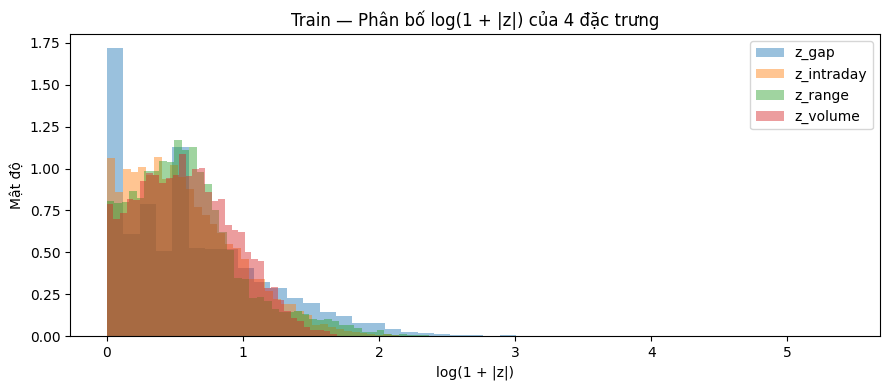

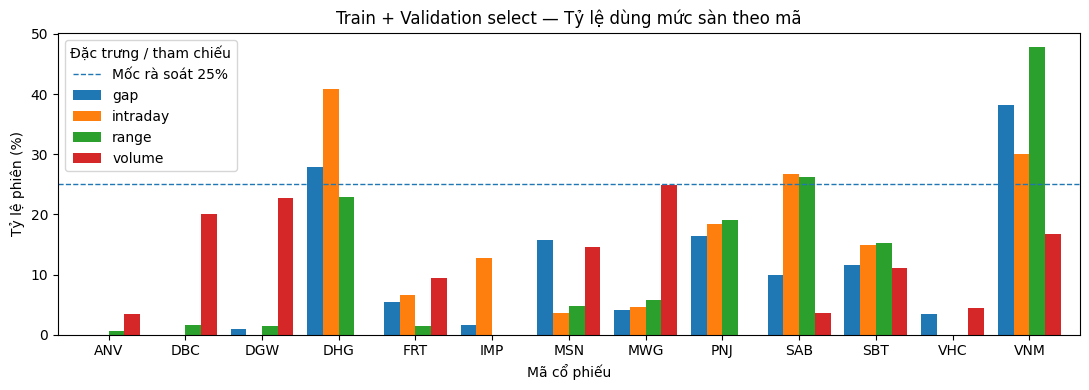

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
for col in ZS:
    ax.hist(np.log1p(train[col].abs()), bins=45, alpha=0.45, label=col, density=True)
ax.set(title="Train — Phân bố log(1 + |z|) của 4 đặc trưng", xlabel="log(1 + |z|)", ylabel="Mật độ")
ax.legend()
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "04_train_feature_scale.png", dpi=130)
plt.show()

floor_wide = floor_by_ticker.pivot(index="ticker", columns="feature", values="floor_pct").sort_index()
ax = floor_wide.plot(kind="bar", figsize=(11, 4), width=0.82)
ax.axhline(QA_FLOOR_PCT, linestyle="--", linewidth=1, label="Mốc rà soát 25%")
ax.set(title="Train + Validation select — Tỷ lệ dùng mức sàn theo mã", ylabel="Tỷ lệ phiên (%)", xlabel="Mã cổ phiếu")
ax.legend(title="Đặc trưng / tham chiếu")
plt.xticks(rotation=0)
plt.tight_layout()
ax.figure.savefig(OUTPUT_DIR / "04_floor_usage_by_ticker.png", dpi=130)
plt.show()

In [12]:
qa_df = pd.DataFrame(checks)
qa_df.to_csv(OUTPUT_DIR / "04_integrity_checks.csv", index=False, encoding="utf-8-sig")
scale_table.to_csv(OUTPUT_DIR / "04_train_feature_scales.csv", index=False, encoding="utf-8-sig")
review.to_csv(OUTPUT_DIR / "04_gap_sessions_to_review.csv", index=False, encoding="utf-8-sig")
floor_by_ticker.to_csv(OUTPUT_DIR / "04_floor_by_ticker.csv", index=False, encoding="utf-8-sig")
sensitivity.to_csv(OUTPUT_DIR / "04_floor_sensitivity.csv", index=False, encoding="utf-8-sig")

counts = all_df.groupby("split", observed=True).agg(
    n_source=("ticker", "size"), n_model_ready=("is_model_ready", "sum")
).reset_index()
counts.to_csv(OUTPUT_DIR / "04_readiness_by_split.csv", index=False, encoding="utf-8-sig")

warnings = []
if mask_big_gap_train.any():
    warnings.append(f"Có {int(mask_big_gap_train.sum())} phiên Train với |z_gap| > {QA_GAP_ABS_Z:g}; rà giá gốc và thang chuẩn hóa, không tự loại.")
if floor_by_ticker["review_floor_pct_gt_25"].any():
    warnings.append(f"Có {int(floor_by_ticker['review_floor_pct_gt_25'].sum())} tổ hợp mã–đặc trưng sử dụng sàn >{QA_FLOOR_PCT:g}% (Train + Val select).")
warnings += [
    "Tên trạng thái 'invalid_raw_feature' cho phiên đầu mỗi mã nên được diễn giải thành 'missing_previous_close' — OHLCV không sai.",
    "Không có kiểm chứng độc lập nguồn giá cho các phiên gap cực trị trong Bước 04.",
    "Tính độc lập của giai đoạn Test trước ảnh hưởng notebook cũ vẫn cần được xác minh trước đánh giá cuối.",
]

qa_verdict = {
    "step": "04_feature_validation",
    "result": "TECHNICAL_PASS_WITH_METHODOLOGY_WARNINGS",
    "config_w": W,
    "train_rows_ready": int(len(train)),
    "val_select_rows_ready": int(len(val_select)),
    "full_data_rows_structurally_checked": int(len(all_df)),
    "test_policy": "Test only checked for arithmetic integrity; no exploratory distributions or model selection",
    "gap_flag_threshold_for_review_only": QA_GAP_ABS_Z,
    "n_large_gap_train": int(mask_big_gap_train.sum()),
    "large_gap_train_share_all_features_squared_pct": float(share_big_gap_sq),
    "qa_checks_passed": int(len(qa_df)),
    "warnings": warnings,
    "next": "Rà các phiên gap lớn và sự lệch thang theo mã; chỉ thử cấu hình/mô hình trên Train và Val select, không dùng Val calibrate/Test",
}
with (OUTPUT_DIR / "04_validation_verdict.json").open("w", encoding="utf-8") as f:
    json.dump(qa_verdict, f, ensure_ascii=False, indent=2)

report_lines = [
    "# Báo cáo Bước 04 — Kiểm tra đặc trưng (Thí nghiệm 1)",
    "",
    "**Kết luận:** PASS về toán học và toàn vẹn dữ liệu; CẦN RÀ về phương pháp trước khi chốt mô hình.",
    "",
    f"- Cửa sổ: W={W} giá trị quá khứ cùng mã; MAD × {FACTOR}; mức sàn học trên Train (phân vị {Q:.0%} của thang MAD dương).",
    f"- Đã kiểm tra toàn bộ {len(all_df):,} dòng về số học. Không dùng Validation calibrate hoặc Test để điều chỉnh thiết kế.",
    f"- Số phiên đủ điều kiện Train: {len(train):,}; Validation select: {len(val_select):,}.",
    f"- {int(mask_big_gap_train.sum())} phiên Train có |z_gap|>{QA_GAP_ABS_Z:g}; chiếm {share_big_gap_sq:.2f}% tổng bình phương bốn trục của Train.",
    "",
    "## Kết quả kiểm tra kỹ thuật",
    *[f"- PASS: {row['check']}" for row in checks],
    "",
    "## Những điểm cần rà soát (không phải lỗi đã được chứng minh)",
    *[f"- {warning}" for warning in warnings],
    "",
    "## Thứ tự xử lý tiếp",
    "1. Rà lại nguồn hoặc logic dữ liệu của các phiên gap cực trị nhưng chưa sửa hay xóa OHLCV.",
    "2. Kiểm tra độ nhạy của mức sàn và ảnh hưởng theo mã; không chọn cấu hình bằng số cảnh báo hoặc F1 proxy.",
    "3. Khi nghiên cứu mô hình chung IF, AE, LOF, đối chiếu trên Train/Validation select; chỉ sau khi khóa cấu hình mới tính ngưỡng trên Validation calibrate.",
    "4. Không dùng kết quả Test để chọn thiết kế. Chỉ báo cáo kết quả Test theo phương án đã khóa và ghi giới hạn về tính độc lập nếu có.",
    "",
    "**Lưu ý:** Các mốc rà soát |z_gap|>30 và 25% dùng sàn không phải ngưỡng bất thường hoặc tiêu chuẩn tối ưu.",
]
(OUTPUT_DIR / "04_feature_validation_report.md").write_text("\n".join(report_lines) + "\n", encoding="utf-8")

print("\n=== TÓM TẮT BƯỚC 04 ===")
print("Kiểm tra PASS:", len(qa_df))
print("Kết luận: kỹ thuật đạt, cảnh báo phương pháp cần rà trên phần phát triển")
for warning in warnings:
    print("  [CANH BAO]", warning)
print("\nBáo cáo và bảng đã lưu tại:", OUTPUT_DIR.resolve())


=== TÓM TẮT BƯỚC 04 ===
Kiểm tra PASS: 8
Kết luận: kỹ thuật đạt, cảnh báo phương pháp cần rà trên phần phát triển
  [CANH BAO] Có 14 phiên Train với |z_gap| > 30; rà giá gốc và thang chuẩn hóa, không tự loại.
  [CANH BAO] Có 7 tổ hợp mã–đặc trưng sử dụng sàn >25% (Train + Val select).
  [CANH BAO] Tên trạng thái 'invalid_raw_feature' cho phiên đầu mỗi mã nên được diễn giải thành 'missing_previous_close' — OHLCV không sai.
  [CANH BAO] Không có kiểm chứng độc lập nguồn giá cho các phiên gap cực trị trong Bước 04.
  [CANH BAO] Tính độc lập của giai đoạn Test trước ảnh hưởng notebook cũ vẫn cần được xác minh trước đánh giá cuối.

Báo cáo và bảng đã lưu tại: D:\LUẬN VĂN\stock-news-anomaly-project\Stocks\notebooks\outputs\04_feature_validation
